# Validação com dados de laboratório

Jansen, Fabre e Tengesdal com o fechamento de bolhas da tese e com o arrasto físico; a numérica à escala de 1 atm. Resumo por `mfsim val <corrida> --plot`.

Issues ilustradas (índice em [docs/issues/INDEX.md](../../docs/issues/INDEX.md)):
- [030](../../docs/issues/030-validacao-laboratorio.md)
- [031](../../docs/issues/031-numerica-a-1-atm.md)

*Nenhuma simulação corre aqui: as corridas vêm de `notebooks/data` (dados históricos, 2026-10)
e dos lotes `batches/*.json` (`mfsim batch`); o notebook só lê e desenha.*

In [1]:
import numpy as np, matplotlib.pyplot as plt, os, json, warnings

warnings.filterwarnings("ignore")
from mfsim.fluid import Fluid
from mfsim.runs import find_run, load_run

fluid = Fluid(rhoL0=900.0, rhoG0=1.2, muL=2e-3, muG=1.8e-5, gammaL=100.0, gammaG=1.05, P0=1e5, sigma=0.05)
D = 0.05
A = np.pi * D**2 / 4
P_out = 4.0
qL = 0.3 * 900 * A
qG = 0.1 * fluid.rhoG((P_out + 1) * 1e5) * A


def datafile(fname):
    """Caminho de uma corrida gravada (notebooks/data ou runs/), ou None se não existir."""
    try:
        return find_run(fname)
    except FileNotFoundError:
        print("trajetória não encontrada:", fname)
        return None


def blowdowns(T_, P_in, min_gap=200.0):
    """Instantes dos blowdowns: mínimos locais da pressão na entrada abaixo de 30 % da
    faixa (separados por pelo menos min_gap s; um blowdown tem mínimos secundários nos
    100 s seguintes). Mais robusto do que contar picos de vazão."""
    lvl = P_in.min() + 0.3 * (P_in.max() - P_in.min())
    low = P_in < lvl
    out = []
    i = 0
    while i < T_.size:
        if low[i]:
            j = i
            while j < T_.size and low[j]:
                j += 1
            k = i + int(np.argmin(P_in[i:j]))
            if not out or T_[k] - out[-1] > min_gap:
                out.append(T_[k])
            i = j
        else:
            i += 1
    return np.array(out)


def cycle_stats(T_, P_in, q_out):
    """(número de blowdowns, período médio entre blowdowns [s], pico máximo de líquido após t = 100 s)."""
    tb = blowdowns(T_, P_in)
    per = float(np.mean(np.diff(tb))) if tb.size > 1 else np.nan
    return tb.size, per, float(q_out[T_ > 100].max())


def load_blocked_run(f):
    """Corrida gravada (partida bloqueada ou linha fechada) pelo carregador único
    `mfsim.runs.load_run` (reconstrói o caso do `meta` com os defaults deste notebook, ou de
    `case_json` nas corridas novas) e os balanços de massa; era uma cópia desta lógica."""
    r = load_run(f)
    return dict(
        meta=r.meta,
        case=r.case,
        model=r.model,
        res=r.res,
        T=r.T,
        p=r.pipe(0),
        ib=r.ib,  # célula no início do joelho
        balL=r.balance("L"),
        balG=r.balance("G"),
        acc=r.acc,  # integral BDF-consistente dos fluxos de contorno
        p_last=r.p_last,  # duto que termina no separador (rede: o último)
        aG_riser_base=r.aG_riser_base(),
    )

## Casos e resultados

Casos de bancada com ciclo medido (Jansen–Shoham–Taitel 1996, Fabre et al. 1990 via Tengesdal 2002,
Tengesdal 2002 instalação grande), montados com `severe_slug_case` a partir de linha fechada
(`start="shut_in"`), fechamentos fixos com as regras físicas e os dois fechamentos de bolhas:
o da tese (`bubble_drag="tese"`) e o físico (`"fisico"`, arrasto = empuxo na velocidade terminal
de Mendelson). Ver o README (secção "Validação com dados de laboratório") para as fontes e os achados.

In [2]:
LAB_REF = {
    "jansen": dict(periodo=46.6, P_min=111.0, P_max=133.0, nome='Jansen 1996 (1", riser 3 m; U_LS 0.096, U_GSO 0.075)'),
    "fabre2": dict(
        periodo=137.0, P_min=126.0, P_max=235.0, nome='Fabre 1990 caso 2 (2", riser 13.5 m; vSL 0.13, vSG0 0.20)'
    ),
    "fabre1": dict(
        periodo=70.0, P_min=128.0, P_max=210.0, nome='Fabre 1990 caso 1 (2", riser 13.5 m; vSL 0.13, vSG0 0.45)'
    ),
    "teng1": dict(
        periodo=79.0,
        P_min=121.0,
        P_max=222.0,
        nome='Tengesdal 2002 teste 1 (3", riser 14.6 m, óleo; vSL 0.32, vSG 0.35)',
    ),
}
runs_lab = {}
for key in LAB_REF:
    for closure in ("tese", "fisico"):
        f = datafile(f"severe_slug_lab_{key}_{closure}.npz")
        if f is None:
            continue
        r_ = load_blocked_run(f)
        mb = r_["meta"]
        T_ = r_["T"]
        P1 = r_["p"]["out"]["P_bar"][1] * 100.0
        q_ = r_["p_last"]["out"]["qL"][-1]
        sel = T_ > 0.2 * T_[-1]
        per_ref = LAB_REF[key]["periodo"]
        amp = P1[sel].max() - P1[sel].min()
        tb = blowdowns(T_[sel], P1[sel], min_gap=0.3 * per_ref) if amp > 5.0 else np.array([])
        per = float(np.mean(np.diff(tb))) if tb.size > 1 else np.nan
        runs_lab[(key, closure)] = dict(
            T=T_,
            P=P1,
            q=q_,
            per=per,
            nb=tb.size,
            P_min=P1[sel].min(),
            P_max=P1[sel].max(),
            q_max=q_[sel].max(),
            n_steps=mb.get("n_steps"),
            parcial=bool(mb.get("parcial", False)),
        )
if runs_lab:
    print(
        f"{'caso':62s} {'bolhas':7s} {'período (exp)':>16s} {'P_in kPa (exp)':>22s} {'pico qL':>8s} {'blowdowns':>9s} {'passos':>7s}"
    )
    for (key, closure), r in runs_lab.items():
        ref = LAB_REF[key]
        print(
            f"{ref['nome']:62s} {closure:7s} {r['per']:6.1f} s ({ref['periodo']:5.1f}) {r['P_min']:6.1f}-{r['P_max']:6.1f} ({ref['P_min']:.0f}-{ref['P_max']:.0f}) {r['q_max']:8.2f} {r['nb']:9d} {str(r['n_steps']):>7s}{' (parcial)' if r['parcial'] else ''}"
        )
else:
    print("sem trajetórias de laboratório em notebooks/data (severe_slug_lab_*.npz)")

trajetória não encontrada: severe_slug_lab_fabre1_tese.npz


trajetória não encontrada: severe_slug_lab_teng1_tese.npz


caso                                                           bolhas     período (exp)         P_in kPa (exp)  pico qL blowdowns  passos
Jansen 1996 (1", riser 3 m; U_LS 0.096, U_GSO 0.075)           tese     119.6 s ( 46.6)  122.2- 132.8 (111-133)     0.21         3   63349
Jansen 1996 (1", riser 3 m; U_LS 0.096, U_GSO 0.075)           fisico    62.6 s ( 46.6)   99.1- 132.6 (111-133)     0.79         7   98214
Fabre 1990 caso 2 (2", riser 13.5 m; vSL 0.13, vSG0 0.20)      tese       nan s (137.0)  145.1- 237.0 (126-235)     1.10         1   43735
Fabre 1990 caso 2 (2", riser 13.5 m; vSL 0.13, vSG0 0.20)      fisico   135.8 s (137.0)  105.2- 237.9 (126-235)     8.50         8  117508
Fabre 1990 caso 1 (2", riser 13.5 m; vSL 0.13, vSG0 0.45)      fisico   104.4 s ( 70.0)  121.3- 167.2 (128-210)     3.21         8    6711
Tengesdal 2002 teste 1 (3", riser 14.6 m, óleo; vSL 0.32, vSG 0.35) fisico    63.7 s ( 79.0)  123.1- 232.9 (121-222)    16.69        10   50439


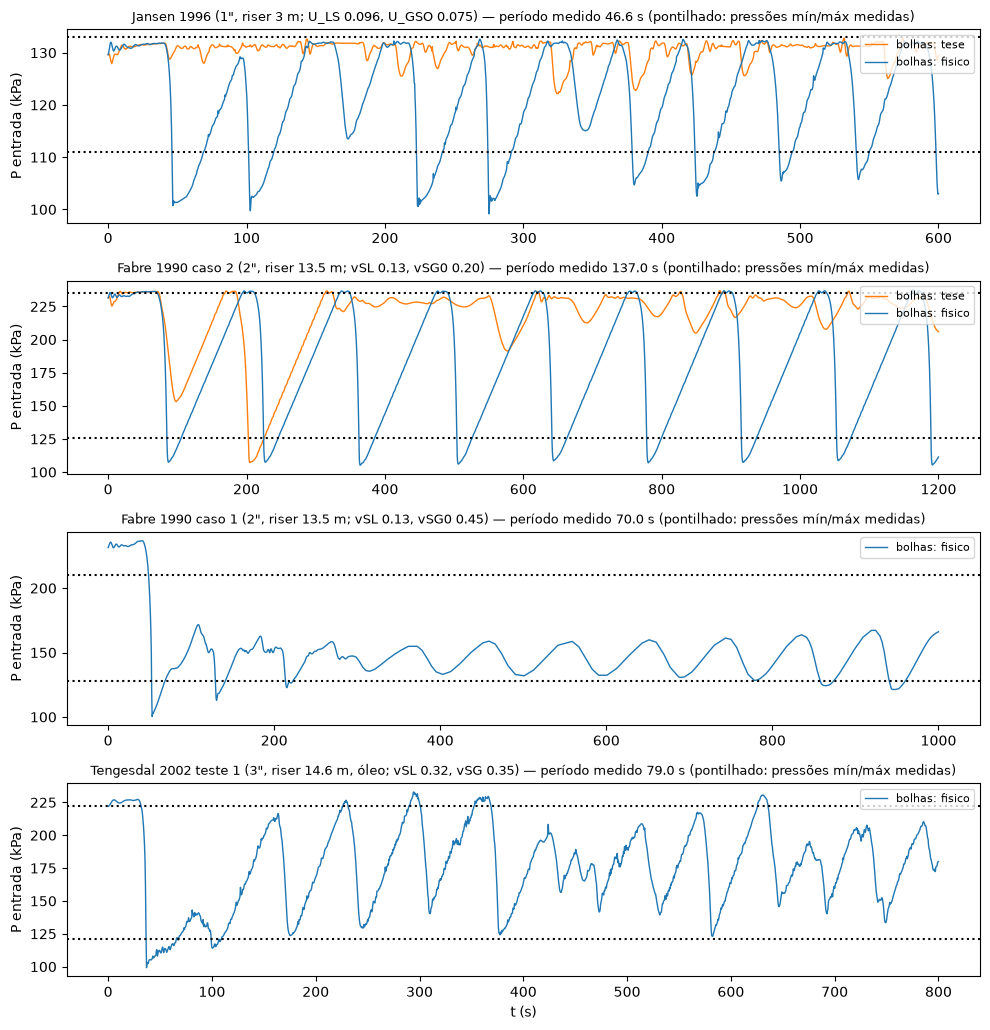

In [3]:
if runs_lab:
    keys = [k for k in LAB_REF if any(kk[0] == k for kk in runs_lab)]
    fig, axs = plt.subplots(len(keys), 1, figsize=(10, 2.6 * len(keys)), squeeze=False)
    for ax, key in zip(axs[:, 0], keys):
        for closure, c in (("tese", "C1"), ("fisico", "C0")):
            if (key, closure) in runs_lab:
                r = runs_lab[(key, closure)]
                ax.plot(r["T"], r["P"], c, lw=1, label=f"bolhas: {closure}")
        ax.axhline(LAB_REF[key]["P_min"], ls=":", c="k")
        ax.axhline(LAB_REF[key]["P_max"], ls=":", c="k")
        ax.set_title(
            f"{LAB_REF[key]['nome']} — período medido {LAB_REF[key]['periodo']} s (pontilhado: pressões mín/máx medidas)",
            fontsize=9,
        )
        ax.set_ylabel("P entrada (kPa)")
        ax.legend(fontsize=8, loc="upper right")
    axs[-1, 0].set_xlabel("t (s)")
    fig.tight_layout()